In [ ]:
print("네트워크 트래픽 이상 탐지 프로젝트 시작")
print("목표 : 정상 트래픽과 이상 트래픽 구분하기")

네트워크 트래픽 이상 탐지 프로젝트 시작
목표 : 정상 트래픽과 이상 트래픽 구분하기


네트워크 트래픽 이상 탐지 프로젝트

1. 프로젝트 목적
- 네트워크 트래픽 데이터를 분석, 정상/이상 트래픽 구분

2. 프로젝트 배경
- 네트워크 엔지니어링 경험을 바탕으로
네트워크 데이터 분석 및 이상 탐지 역량 올리기

3. 사용도구
- Python
- Google Colab
- pandas
- matplotlib
- scikit-learn

4. 분석 과정

* 데이터 수집
* 데이터 정리
* 탐색적 데이터 분석
* 머신 러닝
* 결과 평가

In [ ]:
import pandas as pd

date = {
    "device" : ["SW-01", "SW-01", "RT-01", "RT-01"],
    "interface" : ["Gi1/0/1", "Gi1/0/2", "Gi0/0/0", "Gi0/0/1"],
    "traffic_mbps" : [120, 950, 300, 870],
    "status" : ["normal", "check", "normal", "check"]
}

df = pd.DataFrame(date)

print(df)


  device interface  traffic_mbps  status
0  SW-01   Gi1/0/1           120  normal
1  SW-01   Gi1/0/2           950   check
2  RT-01   Gi0/0/0           300  normal
3  RT-01   Gi0/0/1           870   check
전체 데이터 개수: 4
평균 트래픽: 560.0 Mbps
최대 트래픽: 950 Mbps


In [ ]:
print("전체 데이터 개수:", len(df))
print("평균 트래픽:", df["traffic_mbps"].mean(), "Mbps")
print("최대 트래픽:", df["traffic_mbps"].max(), "Mbps")

전체 데이터 개수: 4
평균 트래픽: 560.0 Mbps
최대 트래픽: 950 Mbps


In [ ]:
print(df["interface"])
print(df["traffic_mbps"])

0    Gi1/0/1
1    Gi1/0/2
2    Gi0/0/0
3    Gi0/0/1
Name: interface, dtype: object
0    120
1    950
2    300
3    870
Name: traffic_mbps, dtype: int64


In [ ]:
high_traffic = df[df["traffic_mbps"] > 500]

print(high_traffic)

  device interface  traffic_mbps status
1  SW-01   Gi1/0/2           950  check
3  RT-01   Gi0/0/1           870  check


In [ ]:
result = df[
    (df["traffic_mbps"] > 500) &
    (df["status"] == "check")
]

print(result)

  device interface  traffic_mbps status
1  SW-01   Gi1/0/2           950  check
3  RT-01   Gi0/0/1           870  check


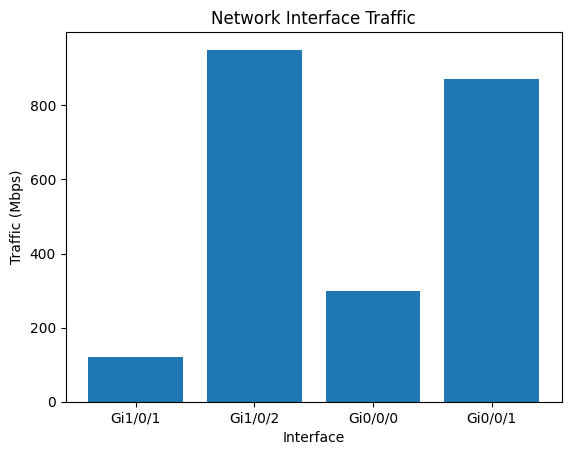

In [ ]:
import matplotlib.pyplot as plt

plt.bar(df["interface"], df["traffic_mbps"])
plt.xlabel("Interface")
plt.ylabel("Traffic (Mbps)")
plt.title("Network Interface Traffic")
plt.show()

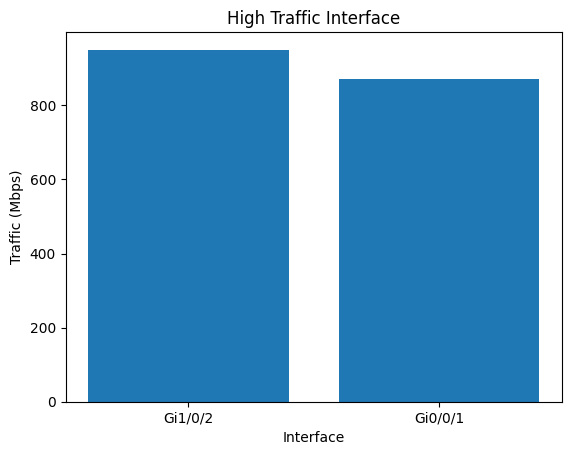

In [ ]:
high_traffic = df[df["traffic_mbps"] > 500]

plt.bar(high_traffic["interface"], high_traffic["traffic_mbps"])
plt.xlabel("Interface")
plt.ylabel("Traffic (Mbps)")
plt.title("High Traffic Interface")
plt.show()

In [ ]:
device_avg = df.groupby("device")["traffic_mbps"].mean()

print(device_avg)

device
RT-01    585.0
SW-01    535.0
Name: traffic_mbps, dtype: float64


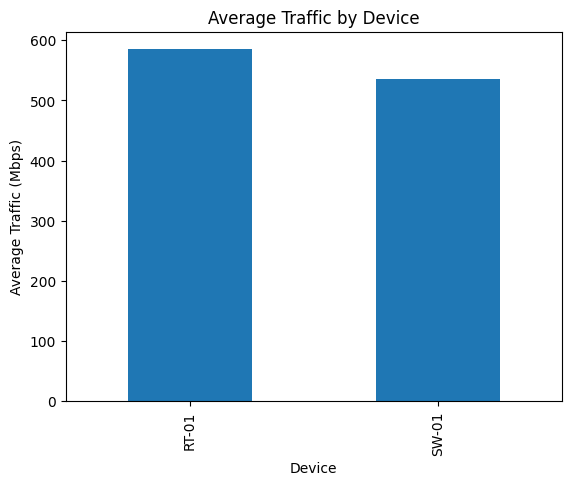

In [ ]:
device_avg.plot(kind="bar")

plt.xlabel("Device")
plt.ylabel("Average Traffic (Mbps)")
plt.title("Average Traffic by Device")
plt.show()

In [ ]:
print(df.head())

  device interface  traffic_mbps  status
0  SW-01   Gi1/0/1           120  normal
1  SW-01   Gi1/0/2           950   check
2  RT-01   Gi0/0/0           300  normal
3  RT-01   Gi0/0/1           870   check


In [ ]:
print(f'데이터 크기 : {df.shape}')
print(f'행 개수 : {df.shape[0]}')
print(f'열 개수 : {df.shape[1]}')

데이터 크기 : (4, 4)
행 개수 : 4
열 개수 : 4


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   device        4 non-null      object
 1   interface     4 non-null      object
 2   traffic_mbps  4 non-null      int64 
 3   status        4 non-null      object
dtypes: int64(1), object(3)
memory usage: 260.0+ bytes


In [ ]:
print(df.describe())

       traffic_mbps
count      4.000000
mean     560.000000
std      412.067956
min      120.000000
25%      255.000000
50%      585.000000
75%      890.000000
max      950.000000


In [20]:
import zipfile

zip_path = "/content/MachineLearningCSV.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    file_list = zip_ref.namelist()

print("압출 파일 안의 CSV 목록 :")
for file in file_list:
    print(file)

압출 파일 안의 CSV 목록 :
MachineLearningCVE/
MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
